# 🐕 Dogebone 02: a trained model of DOGE's direction after Musk's DOGE posts

**Question.** On a day Elon Musk posts about DOGE, will DOGE close **higher or lower** *h* days later (h = 1, 3, 7)? How sure is the model (**conviction**)?

Notebook 01 scored posts with a hand-built keyword lexicon and checked the calls. This notebook **trains a model** on Musk's 2021 DOGE posts
plus the market state, then **tests it on data it never saw**:

| Test | Trained on | Tested on |
|---|---|---|
| **Held-out months** (pre-registered) | Post days in Jan–Aug 2021 whose outcome was known by Aug 31 | Every post day in Sep–Dec 2021 |
| **Walk-forward** | All earlier post days, refit at the start of every month | Each month that has at least 15 earlier post days with known outcomes (Apr–Dec in 2021) |

| Section | What it does |
|---|---|
| 1–2 | Setup, then one row per **post day** with text and market features (all known at the anchor close) |
| 3 | The model: L2 logistic regression, fit on Jan–Aug |
| 4 | **Test 1:** held-out Sep–Dec, post day by post day |
| 5 | **Test 2:** walk-forward, vs. no-skill, majority-class and momentum baselines |
| 6 | Is it the words or the market? Feature ablation and permutation tests |
| 7 | Does conviction mean anything? |
| 8 | Final model on all of 2021 → `models/*.json` |
| 9 | **Use it:** score new posts with `Predictor` |
| 10 | Export charts and `presentation/model_findings.md` |

**Rules we committed to before testing:** the feature list, the penalty (`L2 = 5`), the horizons, and the focus horizon (1 day) are fixed.
Nothing is tuned on the test months. All three horizons are reported, not just the best one.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "dogebone").exists())
sys.path.insert(0, str(ROOT / "src"))

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from dogebone import Config, model as M, pipeline, plots, report

pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 80)
plots.use_style()

cfg = Config(analysis_start="2021-01-01", analysis_end="2021-12-31", train_end="2021-08-31", horizons=(1, 3, 7))
FOCUS_H = 1             # headline horizon, fixed before testing (same as notebook 01)
L2 = M.DEFAULT_L2       # ridge penalty, fixed a priori
FIRST_TEST = "2021-03-01"  # walk-forward: first month tried; months with < 15 earlier post days are skipped
N_PERM = 300            # shuffles per permutation test
print("Repo root found:", ROOT.name)

Repo root found: dogebone


## 2. From posts to post days

Prices are daily, so every DOGE post sharing an anchor close becomes **one row** (a *post day*). Each feature is known at the anchor close
or at post time, whichever is later:

| Feature | Meaning |
|---|---|
| `lex_score` | Lexicon sentiment of the day's posts (notebook 01's daily score, −1 to +1) |
| `lex_any` | Did any post use a sentiment word? (only about a quarter of post days do) |
| `n_posts_log` | How many DOGE posts that day, as log(1 + n) |
| `text_share` | Share of posts that say "Doge" outright, vs. replies that only tag a DOGE account |
| `has_original` | At least one original post (shown to all followers), not only replies |
| `gap_days_log` | Days since the previous DOGE post day, as log(1 + d), capped at 30 |
| `mom_1d`, `mom_7d` | DOGE return over the 1 and 7 days into the anchor close |
| `vol_7d` | Standard deviation of daily log returns over the last 7 days |
| `dd_30d` | Distance below the 30-day high |

The target `y_hd` is 1 if DOGE closed higher *h* days after the anchor close, otherwise 0. Likes and reposts are **excluded**,
because they keep accumulating after the post and partly reflect the price reaction (look-ahead).

In [2]:
prep = pipeline.prepare(cfg)
DATA_MODE = prep.data_mode
if DATA_MODE != "raw":
    display(Markdown("> ## ⚠️ Running on SYNTHETIC sample data. Don't present these results."))

events = M.build_event_features(prep.posts, prep.prices["close"], cfg.horizons, username="elonmusk")
events["period"] = np.where(events["anchor_date"] <= pd.Timestamp(cfg.train_end), "train (Jan–Aug)", "test (Sep–Dec)")
print(f"Data mode: {DATA_MODE}  |  {len(prep.posts)} posts -> {len(events)} post days")
display(events.groupby("period").agg(post_days=("anchor_date", "size"), posts=("n_posts", "sum"),
                                     **{f"up_rate_{h}d": (f"y_{h}d", "mean") for h in cfg.horizons}).style.format(
    {f"up_rate_{h}d": "{:.0%}" for h in cfg.horizons}))
display(events.groupby(events["anchor_date"].dt.to_period("M")).size().rename("post days").to_frame().T)

Data mode: raw  |  105 posts -> 69 post days


,post_days,posts,up_rate_1d,up_rate_3d,up_rate_7d
period,,,,,
test (Sep–Dec),20,29,65%,45%,42%
train (Jan–Aug),49,76,49%,47%,43%


anchor_date,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12
post days,9,8,5,12,6,7,2,4,5,8,3


In [3]:
display(events[M.ALL_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].style.format("{:.3f}"))
display(events[["anchor_date", "n_posts", *M.ALL_FEATURES, "fwd_ret_1d", "y_1d", "texts"]].head(5))

,mean,std,min,50%,max
lex_score,0.075,0.213,-0.429,0.000,0.795
lex_any,0.261,0.442,0.000,0.000,1.000
n_posts_log,0.875,0.297,0.693,0.693,1.792
text_share,0.555,0.468,0.000,0.667,1.000
has_original,0.275,0.450,0.000,0.000,1.000
gap_days_log,1.508,0.735,0.693,1.386,3.434
mom_1d,0.022,0.120,-0.304,-0.005,0.506
mom_7d,0.112,0.607,-0.327,-0.043,4.036
vol_7d,0.101,0.091,0.021,0.071,0.651
dd_30d,-0.248,0.156,-0.562,-0.259,0.000


,anchor_date,n_posts,lex_score,lex_any,n_posts_log,text_share,has_original,gap_days_log,mom_1d,mom_7d,vol_7d,dd_30d,fwd_ret_1d,y_1d,texts
0,2021-02-03,3,0.429131,1.0,1.386294,1.0,1.0,3.433987,0.193086,4.035738,0.650811,-0.185765,0.417595,1.0,"Doge | Dogecoin is the people's crypto | No highs, no lows, only Doge"
1,2021-02-05,2,0.396864,1.0,1.098612,1.0,1.0,1.098612,-0.116090,0.020258,0.285845,-0.116090,0.229076,1.0,Much wow! | @Grimezsz Dogecake
2,2021-02-06,2,0.000000,0.0,1.098612,0.0,0.0,0.693147,0.229076,1.039292,0.193144,0.000000,0.355267,1.0,@Dogecoinrich 🤣🤣 | @Jbuttermost @Dogecoinrich 🤣🤣
3,2021-02-07,3,-0.247559,1.0,1.386294,1.0,1.0,0.693147,0.355267,1.116331,0.198852,0.000000,0.010855,1.0,🎶 Who let the Doge out 🎶 | Ð is for Ðogecoin! Instructional video.\nm.youtub...
4,2021-02-10,1,0.346233,1.0,0.693147,1.0,1.0,1.386294,0.036635,0.943760,0.193299,-0.078724,-0.038578,0.0,"Bought some Dogecoin for lil X, so he can be a toddler hodler"


## 3. The model

**L2-regularized logistic regression** gives P(DOGE up over the next *h* days | features).

- Features are standardized with the **training** mean and SD, so coefficients read as *log-odds per 1 SD*.
- The penalty shrinks every coefficient toward 0 (the base rate), which matters with about 50 training days.
- **Call:** UP if P(up) ≥ 50%, otherwise DOWN.
- **Conviction:** |2·P(up) − 1|. LOW means 40–60%, MEDIUM 60–70% (or 30–40%), HIGH 70%+ (or 30% and below).

Training rows are **purged**: a post day is used for training only if its outcome close (anchor + *h* days) was already known before the
test period starts, so 7-day windows never straddle the train/test boundary.

In [4]:
ho_models, ho_preds = {}, {}
for h in cfg.horizons:
    ho_models[h], ho_preds[h] = M.holdout(events, h, cfg.train_end, M.ALL_FEATURES, L2)
    print(f"{h}d model: trained on {ho_models[h].n_train_} post days ({ho_models[h].train_start_} to {ho_models[h].train_end_}), "
          f"training up-rate {ho_models[h].base_rate_:.0%}")
display(Markdown(f"**Coefficients of the {FOCUS_H}-day model trained on Jan–Aug** (log-odds per 1 SD)"))
display(ho_models[FOCUS_H].coefficients().style.format({"coef_per_sd": "{:+.3f}", "odds_ratio_per_sd": "{:.2f}",
                                                       "train_mean": "{:.3f}", "train_sd": "{:.3f}"}).hide(axis="index"))

1d model: trained on 49 post days (2021-02-03 to 2021-08-29), training up-rate 49%
3d model: trained on 48 post days (2021-02-03 to 2021-08-23), training up-rate 46%
7d model: trained on 48 post days (2021-02-03 to 2021-08-23), training up-rate 42%


**Coefficients of the 1-day model trained on Jan–Aug** (log-odds per 1 SD)

feature,label,coef_per_sd,odds_ratio_per_sd,train_mean,train_sd
text_share,Share of posts saying 'Doge' outright,+0.378,1.46,0.610,0.457
gap_days_log,Days since the previous DOGE post day,-0.358,0.70,1.475,0.698
mom_7d,"DOGE return, last 7 days",+0.319,1.38,0.172,0.704
lex_any,Used any sentiment word,-0.274,0.76,0.286,0.452
vol_7d,"DOGE volatility, last 7 days",+0.200,1.22,0.120,0.100
lex_score,Lexicon sentiment of the day's posts,+0.185,1.20,0.083,0.235
n_posts_log,Number of DOGE posts that day,-0.164,0.85,0.888,0.294
has_original,Has an original post (not only replies),+0.152,1.16,0.367,0.482
dd_30d,Distance below the 30-day high,+0.130,1.14,-0.271,0.162
mom_1d,"DOGE return, last 1 day",+0.046,1.05,0.030,0.138


## 4. Test 1: the held-out months (Sep–Dec 2021)

The models above saw **no data after Aug 31**. Each Sep–Dec post day is predicted exactly once.

| Metric | Meaning |
|---|---|
| `hit_rate` | Share of calls whose direction matched the move |
| `null_hit_rate` | Hit rate expected if the calls were independent of outcomes, given the UP/DOWN mix. **The bar to beat.** |
| `p_value` | One-sided binomial test of the hit rate against `null_hit_rate` |
| `majority_hit_rate` | Always calling whatever happened more often in training |
| `momentum_hit_rate` | "The last *h* days' direction continues" |
| `auc` | Probability that a random up-day got a higher P(up) than a random down-day (0.5 = no ranking skill) |
| `brier_skill` | 1 − Brier / Brier of always forecasting the training up-rate. Above 0 means the probabilities beat the base rate. |

In [5]:
fmt = {"hit_rate": "{:.1%}", "null_hit_rate": "{:.1%}", "edge_pp": "{:+.1f}", "p_value": "{:.3f}", "majority_hit_rate": "{:.1%}",
       "momentum_hit_rate": "{:.1%}", "up_rate": "{:.0%}", "share_called_up": "{:.0%}", "auc": "{:.2f}", "brier": "{:.3f}",
       "brier_ref": "{:.3f}", "brier_skill": "{:+.3f}", "log_loss": "{:.3f}", "mean_ret_when_up": "{:+.2%}", "mean_ret_when_down": "{:+.2%}"}
holdout_scores = pd.DataFrame([M.score_predictions(ho_preds[h], h) for h in cfg.horizons])
display(holdout_scores.style.format(fmt).hide(axis="index"))

horizon_d,n,hit_rate,null_hit_rate,edge_pp,p_value,majority_hit_rate,momentum_hit_rate,up_rate,share_called_up,auc,brier,brier_ref,brier_skill,log_loss,mean_ret_when_up,mean_ret_when_down
1,20,20.0%,39.5%,-19.5,0.982,35.0%,30.0%,65%,15%,0.36,0.342,0.253,-0.350,0.888,-2.92%,+2.98%
3,20,55.0%,52.0%,+3.0,0.483,55.0%,50.0%,45%,30%,0.60,0.242,0.248,+0.024,0.676,-0.70%,+0.12%
7,19,52.6%,57.1%,-4.4,0.735,57.9%,68.4%,42%,5%,0.53,0.256,0.244,-0.050,0.708,-3.66%,+0.65%


anchor_date,n_posts,first post,p_up,direction,conviction_bucket,fwd_ret_1d,actual,hit
2021-09-02 00:00:00,1,@dogecoin_devs Good progress. Applying information theory to currency,36%,DOWN,MEDIUM,+0.42%,UP,0.000000
2021-09-12 00:00:00,3,@SirWoofOfDoge @WholeMarsBlog 🤣🤣,18%,DOWN,HIGH,-5.82%,DOWN,1.000000
2021-09-22 00:00:00,1,@BillyM2k Super important for Doge fees to drop to make things like b,29%,DOWN,HIGH,+0.10%,UP,0.000000
2021-09-28 00:00:00,1,@NewFolderF @dogeofficialceo @BillyM2k 🤣,27%,DOWN,HIGH,+1.01%,UP,0.000000
2021-10-22 00:00:00,1,@UberFacts *In Dogecoin,36%,DOWN,MEDIUM,+2.71%,UP,0.000000
2021-10-23 00:00:00,1,"@mishaboar @DogecoinFdn Neither Jared, nor me, nor anyone I know has",48%,DOWN,LOW,+9.78%,UP,0.000000
2021-10-24 00:00:00,5,@TeslaGong @mishaboar @DogecoinFdn Not recently. What matters imo is,38%,DOWN,MEDIUM,-3.94%,DOWN,1.000000
2021-10-27 00:00:00,2,"@BillyM2k If I send you 2 Doge, will you promise to send me 1 Doge?",41%,DOWN,LOW,+25.94%,UP,0.000000
2021-10-31 00:00:00,1,Tuition is in Dogecoin & u get a discount if u have a dog,60%,UP,LOW,-2.92%,DOWN,0.000000
2021-11-01 00:00:00,1,@dogeofficialceo @Forbes 🤣,50%,DOWN,LOW,+0.61%,UP,0.000000


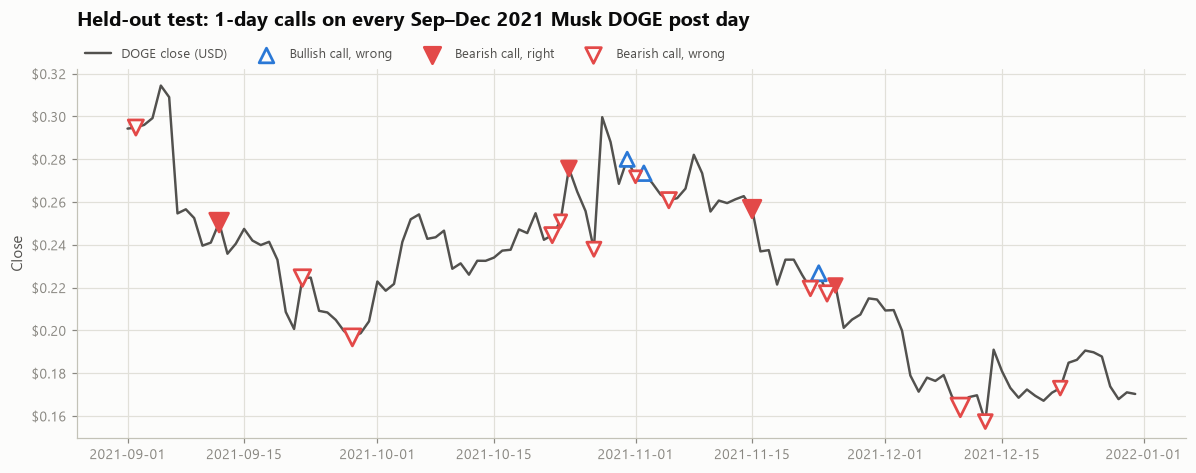

In [6]:
# The test on the current data: every held-out post day, what the model said, and what DOGE did.
t = ho_preds[FOCUS_H].copy()
t["first post"] = t["texts"].str.split(" | ", regex=False).str[0].str.slice(0, 70)
display(t[["anchor_date", "n_posts", "first post", "p_up", "direction", "conviction_bucket", f"fwd_ret_{FOCUS_H}d", "actual", "hit"]]
        .style.format({"p_up": "{:.0%}", f"fwd_ret_{FOCUS_H}d": "{:+.2%}"}).hide(axis="index"))
test_start = (pd.Timestamp(cfg.train_end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
fig_calls = plots.model_calls_timeline(prep.returns, ho_preds[FOCUS_H], test_start, cfg.analysis_end,
                                       title=f"Held-out test: {FOCUS_H}-day calls on every Sep–Dec 2021 Musk DOGE post day")
plt.show()

## 5. Test 2: walk-forward (refit every month)

A single four-month holdout is only about 20 post days. The walk-forward test uses more of the year without ever peeking ahead.
At the start of each month from March, the model is refit on **all earlier post days whose outcome is already known**, then predicts that month's post days.
A month is skipped if fewer than 15 earlier post days have known outcomes. The cell prints which months were actually tested.

Months predicted: Apr–Dec 2021. Skipped: 2021-03 (9 earlier post days with outcomes, need 15)


horizon_d,n,hit_rate,null_hit_rate,edge_pp,p_value,majority_hit_rate,momentum_hit_rate,up_rate,share_called_up,auc,brier,brier_ref,brier_skill,log_loss,mean_ret_when_up,mean_ret_when_down
1,52,50.0%,49.5%,+0.5,0.525,48.1%,40.4%,52%,37%,0.52,0.273,0.261,-0.047,0.744,+7.18%,+1.48%
3,52,61.5%,49.3%,+12.2,0.052,48.1%,55.8%,44%,56%,0.59,0.248,0.267,+0.072,0.690,+6.70%,-3.14%
7,51,49.0%,50.2%,-1.2,0.620,54.9%,58.8%,41%,49%,0.44,0.283,0.258,-0.098,0.769,+16.38%,-1.67%


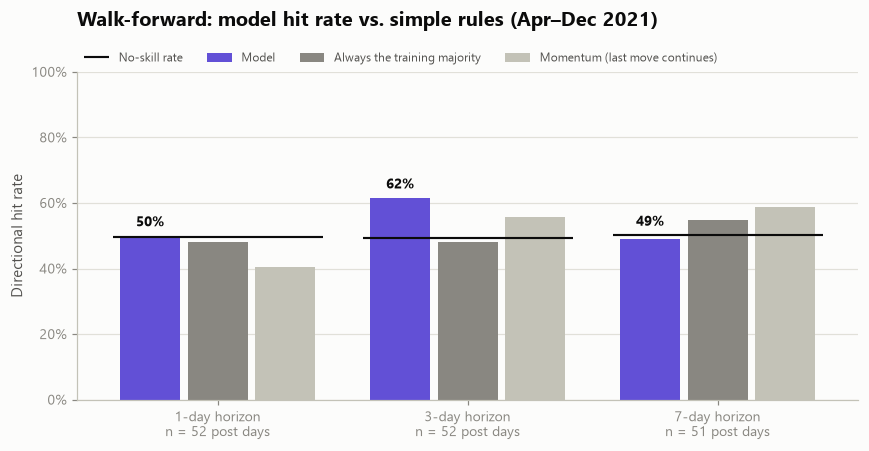

**Hit rate by month predicted** (n in brackets)

horizon_d,1,3,7
fold,,,
2021-04,40% (5),100% (5),80% (5)
2021-05,50% (12),67% (12),58% (12)
2021-06,83% (6),50% (6),0% (6)
2021-07,86% (7),57% (7),57% (7)
2021-08,50% (2),50% (2),50% (2)
2021-09,25% (4),75% (4),75% (4)
2021-10,40% (5),60% (5),20% (5)
2021-11,25% (8),50% (8),57% (7)
2021-12,33% (3),33% (3),33% (3)


In [7]:
wf_preds = {h: M.walk_forward(events, h, M.ALL_FEATURES, L2, first_test=FIRST_TEST) for h in cfg.horizons}
wf_scores = pd.DataFrame([M.score_predictions(wf_preds[h], h) for h in cfg.horizons])
WF_WINDOW = M.tested_window(wf_preds[FOCUS_H])
SKIPPED = wf_preds[FOCUS_H].attrs["skipped_months"]
print(f"Months predicted: {WF_WINDOW}. Skipped: {', '.join(SKIPPED) or 'none'}")
display(wf_scores.style.format(fmt).hide(axis="index"))
fig_base = plots.model_vs_baselines(wf_scores, title=f"Walk-forward: model hit rate vs. simple rules ({WF_WINDOW})")
plt.show()

monthly = pd.concat([wf_preds[h].assign(horizon_d=h) for h in cfg.horizons])
display(Markdown("**Hit rate by month predicted** (n in brackets)"))
display(monthly.groupby(["fold", "horizon_d"])["hit"].agg(lambda s: f"{s.mean():.0%} ({s.notna().sum()})").unstack())

## 6. Is it the words, or the market?

The same two tests with **text-only** and **market-only** feature sets show which half carries what skill there is.
Two permutation tests (walk-forward, all features) ask:

- **Outcomes shuffled:** is *anything* in the features informative?
- **Text shuffled, market kept:** do Musk's words add anything beyond the market state?

In [8]:
wf_grid = M.evaluate_grid(events, cfg.horizons, scheme="walk_forward", l2=L2, first_test=FIRST_TEST)
ho_grid = M.evaluate_grid(events, cfg.horizons, scheme="holdout", train_end=cfg.train_end, l2=L2)
cols = ["features", "horizon_d", "n", "hit_rate", "null_hit_rate", "p_value", "auc", "brier_skill"]
display(Markdown("**Walk-forward**"), wf_grid[cols].style.format(fmt).hide(axis="index"))
display(Markdown("**Held-out Sep–Dec**"), ho_grid[cols].style.format(fmt).hide(axis="index"))

**Walk-forward**

features,horizon_d,n,hit_rate,null_hit_rate,p_value,auc,brier_skill
text + market,1,52,50.0%,49.5%,0.525,0.52,-0.047
text + market,3,52,61.5%,49.3%,0.052,0.59,+0.072
text + market,7,51,49.0%,50.2%,0.620,0.44,-0.098
text only,1,52,51.9%,50.0%,0.445,0.50,-0.034
text only,3,52,55.8%,47.8%,0.155,0.61,+0.055
text only,7,51,49.0%,51.6%,0.693,0.48,-0.049
market only,1,52,36.5%,50.0%,0.982,0.36,-0.002
market only,3,52,40.4%,51.8%,0.963,0.31,-0.000
market only,7,51,56.9%,54.3%,0.413,0.36,-0.039


**Held-out Sep–Dec**

features,horizon_d,n,hit_rate,null_hit_rate,p_value,auc,brier_skill
text + market,1,20,20.0%,39.5%,0.982,0.36,-0.350
text + market,3,20,55.0%,52.0%,0.483,0.60,+0.024
text + market,7,19,52.6%,57.1%,0.735,0.53,-0.050
text only,1,20,25.0%,41.0%,0.958,0.36,-0.265
text only,3,20,60.0%,51.5%,0.297,0.63,+0.043
text only,7,19,52.6%,57.1%,0.735,0.55,-0.038
market only,1,20,30.0%,39.5%,0.865,0.29,-0.107
market only,3,20,55.0%,55.0%,0.591,0.41,-0.030
market only,7,19,57.9%,57.9%,0.596,0.73,+0.022


In [9]:
perm = pd.DataFrame([M.permutation_test(events, h, M.ALL_FEATURES, L2, n_perm=N_PERM, seed=h, shuffle=s, first_test=FIRST_TEST)
                     for s in ("outcome", "text") for h in cfg.horizons])
display(perm.style.format({c: "{:.3f}" for c in perm.columns if perm[c].dtype.kind == "f"}).hide(axis="index"))

horizon_d,shuffle,n,n_perm,hit_rate,null_hit_rate_mean,p_hit_rate,auc,null_auc_mean,p_auc,brier_skill,null_brier_skill_mean,p_brier_skill
1,outcome,52,300,0.500,0.492,0.522,0.516,0.483,0.355,-0.047,-0.075,0.355
3,outcome,52,300,0.615,0.487,0.030,0.589,0.474,0.100,0.072,-0.081,0.017
7,outcome,51,300,0.490,0.513,0.721,0.440,0.475,0.684,-0.098,-0.083,0.585
1,text,52,300,0.500,0.473,0.415,0.516,0.462,0.252,-0.047,-0.057,0.415
3,text,52,300,0.615,0.463,0.030,0.589,0.435,0.033,0.072,-0.057,0.030
7,text,51,300,0.490,0.486,0.545,0.440,0.431,0.465,-0.098,-0.092,0.535


## 7. Does conviction mean anything?

If the probabilities are informative, HIGH-conviction calls should hit more often than LOW ones, and the realized up-rate should track the mean P(up).

In [10]:
conv_tables = {h: M.by_conviction(wf_preds[h], h) for h in cfg.horizons}
for h in cfg.horizons:
    display(Markdown(f"**{h}-day, walk-forward**"),
            conv_tables[h].style.format({"mean_p_up": "{:.0%}", "realized_up_rate": "{:.0%}", "hit_rate": "{:.0%}"}).hide(axis="index"))

**1-day, walk-forward**

conviction_bucket,n,mean_p_up,realized_up_rate,hit_rate
LOW,23,47%,57%,48%
MEDIUM,18,50%,50%,56%
HIGH,11,40%,45%,45%


**3-day, walk-forward**

conviction_bucket,n,mean_p_up,realized_up_rate,hit_rate
LOW,24,51%,50%,62%
MEDIUM,19,54%,42%,58%
HIGH,9,47%,33%,67%


**7-day, walk-forward**

conviction_bucket,n,mean_p_up,realized_up_rate,hit_rate
LOW,25,51%,48%,56%
MEDIUM,14,46%,21%,43%
HIGH,12,46%,50%,42%


## 8. Final model on all of 2021 → `models/`

The deployable model is refit on **every** 2021 post day with a known outcome. Its skill is the out-of-sample skill estimated above,
**not** its in-sample fit. Each horizon is saved as plain JSON (coefficients, training means and SDs, metrics), so it can be read without this repo.

saved models\musk_doge_direction_1d.json  (trained on 69 post days)
saved models\musk_doge_direction_3d.json  (trained on 69 post days)
saved models\musk_doge_direction_7d.json  (trained on 68 post days)


feature,label,coef_per_sd,odds_ratio_per_sd,train_mean,train_sd
mom_7d,"DOGE return, last 7 days",+0.317,1.37,0.112,0.602
n_posts_log,Number of DOGE posts that day,-0.248,0.78,0.875,0.295
lex_any,Used any sentiment word,-0.237,0.79,0.261,0.439
text_share,Share of posts saying 'Doge' outright,+0.208,1.23,0.555,0.464
has_original,Has an original post (not only replies),+0.123,1.13,0.275,0.447
dd_30d,Distance below the 30-day high,+0.111,1.12,-0.248,0.155
lex_score,Lexicon sentiment of the day's posts,+0.108,1.11,0.075,0.211
gap_days_log,Days since the previous DOGE post day,-0.099,0.91,1.508,0.729
vol_7d,"DOGE volatility, last 7 days",+0.073,1.08,0.101,0.091
mom_1d,"DOGE return, last 1 day",-0.047,0.95,0.022,0.119


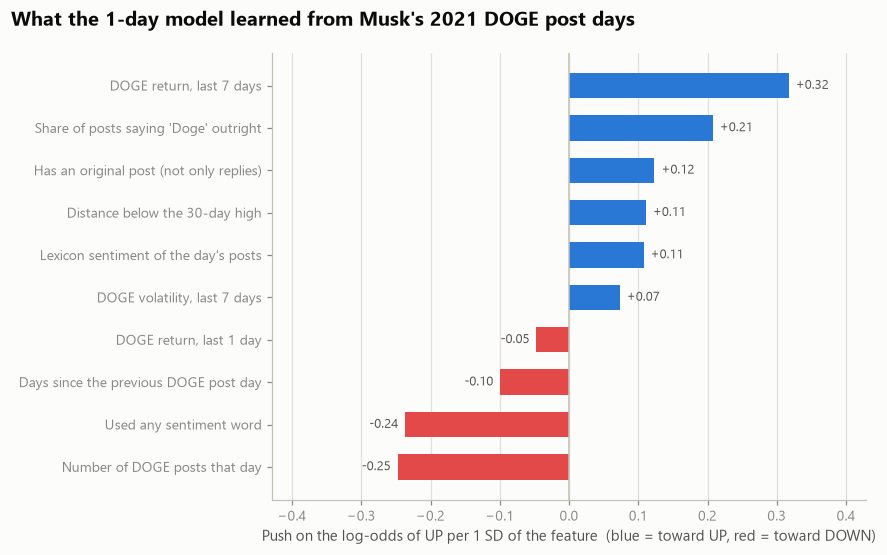

In [11]:
final = {}
model_dir = cfg.root / "models"
for h in cfg.horizons:
    meta = {
        "data_mode": DATA_MODE, "account": "elonmusk", "analysis_window": [cfg.analysis_start, cfg.analysis_end],
        "anchor_mode": cfg.anchor_mode,
        "walk_forward_test": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in M.score_predictions(wf_preds[h], h).items()},
        "heldout_test": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in M.score_predictions(ho_preds[h], h).items()},
        "heldout_window": [test_start, cfg.analysis_end], "walk_forward_months": M.tested_window(wf_preds[h]),
    }
    final[h] = M.fit_final(events, h, M.ALL_FEATURES, L2, **meta)
    path = final[h].save(model_dir / f"musk_doge_direction_{h}d.json")
    print(f"saved {path.relative_to(cfg.root)}  (trained on {final[h].n_train_} post days)")
coef_final = final[FOCUS_H].coefficients()
display(coef_final.style.format({"coef_per_sd": "{:+.3f}", "odds_ratio_per_sd": "{:.2f}", "train_mean": "{:.3f}",
                                 "train_sd": "{:.3f}"}).hide(axis="index"))
fig_coef = plots.model_coefficients(coef_final, title=f"What the {FOCUS_H}-day model learned from Musk's 2021 DOGE post days")
plt.show()

## 9. Use it: score new posts

`Predictor` loads the saved models plus the repo's prices and lexicon. Give it the post text and its UTC time. It needs a DOGE close for the
post's anchor date and about 10 closes before it (add newer prices to `data/raw/prices/` to score recent posts). When later prices exist, it also shows
what actually happened. Passing a DataFrame with a `message_type` column ('update' / 'reply') reproduces the training features exactly.
Otherwise a post starting with "@" counts as a reply.

First, an honest demo: Musk's last DOGE posts of 2021 scored by the **Jan–Aug model**, which had never seen them.

In [12]:
oos = M.Predictor(ho_models, prep)
last_days = prep.posts["anchor_date"].drop_duplicates().nlargest(2)
last = prep.posts.loc[prep.posts["anchor_date"].isin(last_days), ["text", "created_at", "message_type"]]
demo = oos.predict(last)
display(demo)
# Same model, same inputs -> must match the held-out predictions in section 4.
check = demo[demo["horizon_d"] == FOCUS_H].merge(ho_preds[FOCUS_H][["anchor_date", "p_up"]], on="anchor_date", suffixes=("", "_test"))
assert np.allclose(check["p_up"], check["p_up_test"], atol=1e-3), check

,anchor_date,horizon_d,p_up,direction,conviction,lexicon_sentiment,matched_terms,top_reasons,actual,actual_return
0,2021-12-13,1,0.419,DOWN,LOW,0.0,,Has an original post (not only replies) = yes (pushes UP); Used any sentimen...,UP,0.213518
1,2021-12-22,1,0.424,DOWN,LOW,0.0,,Days since the previous DOGE post day = 9 (pushes DOWN); Share of posts sayi...,UP,0.068584
2,2021-12-13,3,0.469,DOWN,LOW,0.0,,Has an original post (not only replies) = yes (pushes UP); Number of DOGE po...,UP,0.100179
3,2021-12-22,3,0.357,DOWN,MEDIUM,0.0,,Has an original post (not only replies) = no (pushes DOWN); Share of posts s...,UP,0.101440
4,2021-12-13,7,0.411,DOWN,LOW,0.0,,Has an original post (not only replies) = yes (pushes UP); Number of DOGE po...,UP,0.061953
5,2021-12-22,7,0.297,DOWN,HIGH,0.0,,Has an original post (not only replies) = no (pushes DOWN); Number of DOGE p...,DOWN,-0.029833


In [13]:
# Any post, with the deployed (all-2021) models. Change the text and time and re-run.
pred = M.Predictor.from_repo(cfg=cfg)
pred.predict("Dogecoin is the people's crypto 🚀", posted_at="2021-12-20T15:00:00Z")

,anchor_date,horizon_d,p_up,direction,conviction,lexicon_sentiment,matched_terms,top_reasons,actual,actual_return
0,2021-12-20,1,0.619,UP,MEDIUM,0.64,"people's crypto(+2.0), 🚀(+2.5)",Used any sentiment word = yes (pushes DOWN); Lexicon sentiment of the day's ...,UP,0.022414
1,2021-12-20,3,0.610,UP,MEDIUM,0.64,"people's crypto(+2.0), 🚀(+2.5)",Used any sentiment word = yes (pushes DOWN); Has an original post (not only ...,UP,0.106314
2,2021-12-20,7,0.609,UP,MEDIUM,0.64,"people's crypto(+2.0), 🚀(+2.5)",Has an original post (not only replies) = yes (pushes UP); Lexicon sentiment...,UP,0.123606


## 10. Export for the presentation

In [14]:
fig_dir = cfg.presentation_dir / "figures"
mark = None if DATA_MODE == "raw" else "SYNTHETIC DATA"
figs = {"06_model_vs_baselines": fig_base, "07_model_heldout_calls": fig_calls, "08_model_coefficients": fig_coef}
saved = []
for name, fig in figs.items():
    plots.save(fig, name, cfg.figures_dir, fig_dir, watermark=mark)
    saved.append(f"presentation/figures/{name}.png")

cfg.processed_dir.mkdir(parents=True, exist_ok=True)
events.to_csv(cfg.processed_dir / "model_post_days.csv", index=False)
pd.concat([wf_preds[h].assign(horizon_d=h, test="walk_forward") for h in cfg.horizons]
          + [ho_preds[h].assign(horizon_d=h, test="holdout") for h in cfg.horizons]).to_csv(
    cfg.processed_dir / "model_predictions.csv", index=False)

findings = report.write_model_findings(
    cfg.presentation_dir / "model_findings.md", cfg, DATA_MODE, FOCUS_H, wf_grid, ho_grid, perm, conv_tables[FOCUS_H],
    coef_final, ho_preds[FOCUS_H], n_events=len(events), n_posts=len(prep.posts), figures=saved, l2=L2,
    wf_window=WF_WINDOW, skipped_months=SKIPPED,
)
display(Markdown(findings))

# Model findings (auto-drafted by notebooks/02_direction_model.ipynb)

_Generated 2026-10-20 08:33 UTC from 105 @elonmusk DOGE posts on 69 post days, 2021-01-01 to 2021-12-31. Model: L2 logistic regression (penalty 5, fixed in advance) on post-day text and market features. Focus horizon: 1 day(s), chosen before testing._

## Headline

- Walk-forward (Apr–Dec 2021, refit monthly on earlier months only): the model called the next-1-day direction right **50%** of the time vs. **49%** no-skill (+0.5 pp, p = 0.525, n = 52 post days; AUC 0.52, Brier skill -0.05): **not** distinguishable from chance.
- Held-out Sep–Dec 2021 (trained on Jan–Aug only): the model called the next-1-day direction right **20%** of the time vs. **40%** no-skill (-19.5 pp, p = 0.982, n = 20 post days; AUC 0.36, Brier skill -0.35): **not** distinguishable from chance.
- Against simple rules (walk-forward, 1d): the model beat always calling the training majority (48%) and beat momentum (40%).
- Walk-forward months skipped for too little history: 2021-03 (9 earlier post days with outcomes, need 15).

## Every horizon (text + market features)

| Test | Horizon | n | Model | No-skill | p | Majority rule | Momentum | AUC | Brier skill |
|---|---|---|---|---|---|---|---|---|---|
| walk-forward | 1d | 52 | 50% | 49% | 0.525 | 48% | 40% | 0.52 | -0.05 |
| walk-forward | 3d | 52 | 62% | 49% | 0.052 | 48% | 56% | 0.59 | +0.07 |
| walk-forward | 7d | 51 | 49% | 50% | 0.620 | 55% | 59% | 0.44 | -0.10 |
| held-out | 1d | 20 | 20% | 40% | 0.982 | 35% | 30% | 0.36 | -0.35 |
| held-out | 3d | 20 | 55% | 52% | 0.483 | 55% | 50% | 0.60 | +0.02 |
| held-out | 7d | 19 | 53% | 57% | 0.735 | 58% | 68% | 0.53 | -0.05 |

_Three horizons were tested, so a single p below 0.05 is weak evidence: the Bonferroni bar is 0.017. A Brier skill above 0 means the probabilities beat the training base rate._

## Is it the words or the market? (walk-forward)

| Features | 1d hit / AUC | 3d hit / AUC | 7d hit / AUC |
|---|---|---|---|
| text + market | 50% / 0.52 | 62% / 0.59 | 49% / 0.44 |
| text only | 52% / 0.50 | 56% / 0.61 | 49% / 0.48 |
| market only | 37% / 0.36 | 40% / 0.31 | 57% / 0.36 |

**Permutation tests** (walk-forward, text + market; p = share of shuffled runs at least as good):

- 1d, outcomes shuffled (are any features informative?): hit-rate p = 0.522, AUC p = 0.355 (300 shuffles).
- 3d, outcomes shuffled (are any features informative?): hit-rate p = 0.030, AUC p = 0.100 (300 shuffles).
- 7d, outcomes shuffled (are any features informative?): hit-rate p = 0.721, AUC p = 0.684 (300 shuffles).
- 1d, Musk's text features shuffled, market kept (do the words add anything?): hit-rate p = 0.415, AUC p = 0.252 (300 shuffles).
- 3d, Musk's text features shuffled, market kept (do the words add anything?): hit-rate p = 0.030, AUC p = 0.033 (300 shuffles).
- 7d, Musk's text features shuffled, market kept (do the words add anything?): hit-rate p = 0.545, AUC p = 0.465 (300 shuffles).

## Does conviction mean anything? (walk-forward, 1d)

| Conviction | n | Mean P(up) | Realized up-rate | Hit rate |
|---|---|---|---|---|
| LOW | 23 | 47% | 57% | 48% |
| MEDIUM | 18 | 50% | 50% | 56% |
| HIGH | 11 | 40% | 45% | 45% |

_HIGH = the model is at least 70% sure either way; LOW = between 40% and 60%._

## What the final 1d model learned (fit on all of 2021)

- DOGE return, last 7 days: +0.32 log-odds per SD (toward UP).
- Number of DOGE posts that day: -0.25 log-odds per SD (toward DOWN).
- Used any sentiment word: -0.24 log-odds per SD (toward DOWN).
- Share of posts saying 'Doge' outright: +0.21 log-odds per SD (toward UP).
- Has an original post (not only replies): +0.12 log-odds per SD (toward UP).

## The held-out test, post day by post day (1d)

| Anchor close | First post that day | P(up) | Call | Conviction | Actual | |
|---|---|---|---|---|---|---|
| 2021-09-02 | @dogecoin_devs Good progress. Applying information theory to currency… | 36% | DOWN | MEDIUM | UP | ❌ |
| 2021-09-12 | @SirWoofOfDoge @WholeMarsBlog 🤣🤣 | 18% | DOWN | HIGH | DOWN | ✅ |
| 2021-09-22 | @BillyM2k Super important for Doge fees to drop to make things like b… | 29% | DOWN | HIGH | UP | ❌ |
| 2021-09-28 | @NewFolderF @dogeofficialceo @BillyM2k 🤣 | 27% | DOWN | HIGH | UP | ❌ |
| 2021-10-22 | @UberFacts *In Dogecoin | 36% | DOWN | MEDIUM | UP | ❌ |
| 2021-10-23 | @mishaboar @DogecoinFdn Neither Jared, nor me, nor anyone I know has … | 48% | DOWN | LOW | UP | ❌ |
| 2021-10-24 | @TeslaGong @mishaboar @DogecoinFdn Not recently. What matters imo is … | 38% | DOWN | MEDIUM | DOWN | ✅ |
| 2021-10-27 | @BillyM2k If I send you 2 Doge, will you promise to send me 1 Doge? | 41% | DOWN | LOW | UP | ❌ |
| 2021-10-31 | Tuition is in Dogecoin & u get a discount if u have a dog | 60% | UP | LOW | DOWN | ❌ |
| 2021-11-01 | @dogeofficialceo @Forbes 🤣 | 50% | DOWN | LOW | UP | ❌ |
| 2021-11-02 | @BillyM2k How about my lil doge Floki? He would make a great CEO! His… | 61% | UP | MEDIUM | DOWN | ❌ |
| 2021-11-05 | @dogeofficialceo @BillyM2k 🤣 | 36% | DOWN | MEDIUM | UP | ❌ |
| 2021-11-15 | @dogeofficialceo @daelmor @SenSanders Regretamine, it's like a 100% t… | 24% | DOWN | HIGH | DOWN | ✅ |
| 2021-11-22 | @CoinDesk @binance @egreechee Hey @cz_binance, what's going on with y… | 39% | DOWN | MEDIUM | UP | ❌ |
| 2021-11-23 | @cz_binance @CoinDesk @binance @egreechee I don't use Binance (tried … | 63% | UP | MEDIUM | DOWN | ❌ |
| 2021-11-24 | @BillyM2k @WSBChairman @joannabanananaa @dogeofficialceo @GailAlfarAT… | 35% | DOWN | MEDIUM | UP | ❌ |
| 2021-11-25 | @GailAlfarATX @SpaceX @RGVaerialphotos @cnunezimages @kanyewest @SciG… | 43% | DOWN | LOW | DOWN | ✅ |
| 2021-12-10 | @GailAlfarATX @SawyerMerritt @dogecoin Imbued gold/bronze color would… | 18% | DOWN | HIGH | UP | ❌ |
| 2021-12-13 | @DOGEHOUNDS @HardcoreHistory Overall kill ratio was 19:1, but kill ra… | 42% | DOWN | LOW | UP | ❌ |
| 2021-12-22 | @BillyM2k @jack @gladstein @rahilla @farokh @samkazemian @TheSmarmyBu… | 42% | DOWN | LOW | UP | ❌ |

## Caveats to say out loud

- One account, one year: about 50 out-of-sample post days per horizon, so a 10-point edge is within noise.
- 2021 changed regime (mania to slow bleed). Relationships learned in Feb–May can flip by the autumn.
- Daily closes blur a minutes-scale reaction; posts are anchored to the nearest close (at most 12h of overlap).
- Features and the penalty were fixed before testing; nothing was tuned on the test months.

## Figures exported for slides

- `presentation/figures/06_model_vs_baselines.png`
- `presentation/figures/07_model_heldout_calls.png`
- `presentation/figures/08_model_coefficients.png`


## 11. Caveats

1. **Small sample.** One account and one year give 69 post days, about 50 of them out-of-sample per horizon. A 10-point edge on 50 days is within noise.
2. **Several looks.** Three horizons × three feature sets × two tests. Judge the pre-registered focus horizon, and treat a lone p < 0.05 elsewhere as a lead, not a finding.
3. **Regime change.** Feb–May 2021 was a mania and Sep–Dec a slow bleed. Market features that meant "up" in spring can mean "down" in autumn, so the walk-forward and held-out numbers can disagree.
4. **Daily resolution and anchoring.** A post moves price within minutes; daily closes blur that. `nearest_close` lets at most 12h of pre-post movement in.
5. **Text the model can't see.** Image-only memes, and posts that move DOGE without saying "Doge", are invisible.